# Анализ датасета T_ECD small, за 30 дней
1) Основные характеристики:
    * Проанализируем данные: кол-во пользователей,  кол-во товаров, категорий, подкатегорий.
    * Пропущеные значения: сколько товаров не имеет категории. Разреженность, матрица взаимодействия - сколько реальных пар «пользователь-товар» заполнено по сравнению со всеми возможными комбинациями
    * Ищем ошибочные данные.
    * Выбросы: Пользователи с аномальным кол-вом событий - боты, парсеры, нужно отсеять

2) Поведение признаков:
    * Анализируем категории и подкатегории, ищем схожие категории в данных из ритейла и маркетплейса
    * Анализируем пересечение пользователей из ритейла и маркетплейса

3) Выводы: 
    * Наличие событий пользователей в reatil/marketplace данных, дают возможность кроссдоменной рекомендации. 
    * Существеет возможность рекомендации по категории продукта. 
    * Существеет возможность рекомендации по профилю пользователя, родители, кошатники, уровень дохода. 
    * Товары без категории нельзя рекомендовать, но можно использовать для анализа пользователей.

## Обзор датасета

In [1]:
DATASET_PATH = '../../dataset/T_ECD_Project/raw_data/dataset/small'

In [2]:
import os
import polars as pl
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
import seaborn as sns
import pyarrow

In [3]:
target_dir = Path(DATASET_PATH)

# Рекурсивный обход всех файлов и папок
for path in target_dir.rglob('*'):
    # Можно разделить вывод для файлов и папок
    if path.is_file():
        print(f"📄 Файл: {path.relative_to(target_dir)}")
    elif path.is_dir():
        print(f"📁 Папка: {path.relative_to(target_dir)}")

📄 Файл: brands.pq
📄 Файл: users.pq
📁 Папка: marketplace
📁 Папка: retail
📄 Файл: marketplace/items.pq
📁 Папка: marketplace/events
📄 Файл: retail/items.pq
📁 Папка: retail/events
📄 Файл: marketplace/events/01107.pq
📄 Файл: marketplace/events/01104.pq
📄 Файл: marketplace/events/01091.pq
📄 Файл: marketplace/events/01083.pq
📄 Файл: marketplace/events/01092.pq
📄 Файл: marketplace/events/01098.pq
📄 Файл: marketplace/events/01093.pq
📄 Файл: marketplace/events/01084.pq
📄 Файл: marketplace/events/01099.pq
📄 Файл: marketplace/events/01089.pq
📄 Файл: marketplace/events/01103.pq
📄 Файл: marketplace/events/01094.pq
📄 Файл: marketplace/events/01096.pq
📄 Файл: marketplace/events/01097.pq
📄 Файл: marketplace/events/01086.pq
📄 Файл: marketplace/events/01090.pq
📄 Файл: marketplace/events/01101.pq
📄 Файл: marketplace/events/01111.pq
📄 Файл: marketplace/events/01106.pq
📄 Файл: marketplace/events/01082.pq
📄 Файл: marketplace/events/01095.pq
📄 Файл: marketplace/events/01100.pq
📄 Файл: marketplace/events/01087

## 1 Анализ данных

### 1.1 Проанализируем данные: 

кол-во пользователей,  кол-во товаров, категорий, подкатегорий.

Посмотрим head() для всех таблиц, users, brands, retail/items, retail/events, marketplace/items, marketplace/events

Посмотрим данные пользователей:

In [4]:
df_users = pl.read_parquet(os.path.join(DATASET_PATH, 'users.pq'))
print(df_users.head(3))
print(f"Всего пользователей в таблице: {len(df_users)}")

shape: (3, 3)
┌──────────┬────────────────┬────────┐
│ user_id  ┆ socdem_cluster ┆ region │
│ ---      ┆ ---            ┆ ---    │
│ u64      ┆ u8             ┆ u8     │
╞══════════╪════════════════╪════════╡
│ 77309558 ┆ 21             ┆ 2      │
│ 72517894 ┆ 10             ┆ 90     │
│ 86699708 ┆ 9              ┆ 9      │
└──────────┴────────────────┴────────┘
Всего пользователей в таблице: 3500000


Посмотрим данные брендов:

In [5]:
df_brands = pl.read_parquet(os.path.join(DATASET_PATH, 'brands.pq'))
print(df_brands.head(3))
print(f"Всего брендов: {len(df_brands)}")

shape: (3, 2)
┌──────────┬─────────────────┐
│ brand_id ┆ embedding       │
│ ---      ┆ ---             │
│ u64      ┆ array[f32, 300] │
╞══════════╪═════════════════╡
│ 4        ┆ null            │
│ 34       ┆ null            │
│ 45       ┆ null            │
└──────────┴─────────────────┘
Всего брендов: 29485


Посмотрим данные ритейла:

In [6]:
df_retail_items = pl.read_parquet(os.path.join(DATASET_PATH, 'retail', 'items.pq'))
print(df_retail_items.head(3))
print(f"Всего товаров в Retail: {len(df_retail_items)}")

shape: (3, 6)
┌──────────────┬──────────┬────────────────────┬───────────────────┬───────────┬───────────────────┐
│ item_id      ┆ brand_id ┆ category           ┆ subcategory       ┆ price     ┆ embedding         │
│ ---          ┆ ---      ┆ ---                ┆ ---               ┆ ---       ┆ ---               │
│ str          ┆ u64      ┆ str                ┆ str               ┆ f64       ┆ array[f32, 300]   │
╞══════════════╪══════════╪════════════════════╪═══════════════════╪═══════════╪═══════════════════╡
│ fmcg_10      ┆ 65693    ┆ Office Supplies    ┆ Stationery Paper  ┆ -4.426084 ┆ [-0.135573,       │
│              ┆          ┆ and Educationa…    ┆                   ┆           ┆ 0.049446, …       │
│              ┆          ┆                    ┆                   ┆           ┆ 0.0231…           │
│ fmcg_10000   ┆ 146468   ┆ Cleaning Supplies  ┆ Cleaning and      ┆ -4.083248 ┆ [-0.043275,       │
│              ┆          ┆ and Everyday…      ┆ Detergent         ┆         

In [7]:
df_retail_events = pl.read_parquet(os.path.join(DATASET_PATH, 'retail', 'events', '01082.pq'))
print(df_retail_events.head(3))

shape: (3, 6)
┌────────────────┬──────────┬─────────────┬───────────┬─────────────┬─────────┐
│ timestamp      ┆ user_id  ┆ item_id     ┆ subdomain ┆ action_type ┆ os      │
│ ---            ┆ ---      ┆ ---         ┆ ---       ┆ ---         ┆ ---     │
│ duration[μs]   ┆ u64      ┆ str         ┆ str       ┆ str         ┆ str     │
╞════════════════╪══════════╪═════════════╪═══════════╪═════════════╪═════════╡
│ 1082d 188968µs ┆ 61870822 ┆ fmcg_292242 ┆ search    ┆ view        ┆ android │
│ 1082d 237416µs ┆ 6411253  ┆ fmcg_761291 ┆ catalog   ┆ view        ┆ android │
│ 1082d 240923µs ┆ 15367638 ┆ fmcg_830525 ┆ catalog   ┆ view        ┆ android │
└────────────────┴──────────┴─────────────┴───────────┴─────────────┴─────────┘


Посмотрим данные маркетплейса:

In [8]:
df_market_items = pl.read_parquet(os.path.join(DATASET_PATH, 'marketplace', 'items.pq'))
print(df_market_items.head(3))
print(f"Всего товаров в Retail: {len(df_market_items)}")

shape: (3, 6)
┌────────────────┬──────────┬──────────────┬─────────────────────┬───────────┬─────────────────────┐
│ item_id        ┆ brand_id ┆ category     ┆ subcategory         ┆ price     ┆ embedding           │
│ ---            ┆ ---      ┆ ---          ┆ ---                 ┆ ---       ┆ ---                 │
│ str            ┆ u64      ┆ str          ┆ str                 ┆ f64       ┆ array[f32, 300]     │
╞════════════════╪══════════╪══════════════╪═════════════════════╪═══════════╪═════════════════════╡
│ nfmcg_10000001 ┆ 137356   ┆ null         ┆ null                ┆ 6.06364   ┆ [-0.070853,         │
│                ┆          ┆              ┆                     ┆           ┆ 0.03246, … 0.08217… │
│ nfmcg_10000012 ┆ 53389    ┆ null         ┆ null                ┆ 0.960436  ┆ [-0.091099,         │
│                ┆          ┆              ┆                     ┆           ┆ 0.043168, … 0.0602… │
│ nfmcg_1000002  ┆ 34153    ┆ Fashion      ┆ Hats, Scarves, and  ┆ -1.793113 

In [9]:
df_market_events = pl.read_parquet(os.path.join(DATASET_PATH, 'marketplace', 'events', '01082.pq'))
print(df_market_events.head(3))

shape: (3, 6)
┌────────────────┬──────────┬────────────────┬───────────┬─────────────┬─────────┐
│ timestamp      ┆ user_id  ┆ item_id        ┆ subdomain ┆ action_type ┆ os      │
│ ---            ┆ ---      ┆ ---            ┆ ---       ┆ ---         ┆ ---     │
│ duration[μs]   ┆ u64      ┆ str            ┆ str       ┆ str         ┆ str     │
╞════════════════╪══════════╪════════════════╪═══════════╪═════════════╪═════════╡
│ 1082d 89901µs  ┆ 59328774 ┆ nfmcg_14777696 ┆ u2i       ┆ view        ┆ android │
│ 1082d 163483µs ┆ 66295302 ┆ nfmcg_26098539 ┆ catalog   ┆ view        ┆ android │
│ 1082d 864625µs ┆ 37542104 ┆ nfmcg_10840247 ┆ u2i       ┆ view        ┆ android │
└────────────────┴──────────┴────────────────┴───────────┴─────────────┴─────────┘


**Посмотрим на детали:**

* В базе 3.5 млн пользователей (users.pq).

* В Retail около 250 тыс. товаров с префиксом fmcg_.

* В Marketplace около 2.3 млн товаров с префиксом nfmcg_ (он в 10 раз больше, что логично для маркетплейса против ритейл-магазина у дома).

**Особенности признаков:**

* Цены (price): Они нормализованы (есть отрицательные значения, например -4.42). 
Это стандартная анонимизация/масштабирование (Z-score или min-max со смещением) в коммерческих датасетах, чтобы исследователи не восстановили абсолютную коммерческую тайну в рублях, но при этом сохранили относительную разницу между товарами.

* Категории и пропуски: Как в товарах есть много строк с null в полях category и subcategory, но при этом у них заполнены 300-мерные эмбеддинги (array[f32, 300]).

### 1.2 Пропущеные значения: 

Сколько товаров не имеет категории. 
Разреженность, матрица взаимодействия - сколько реальных пар «пользователь-товар» заполнено по сравнению со всеми возможными комбинациями

Retail. Анализ пропусков в товарах:

In [10]:
null_counts_retail = df_retail_items.null_count()
print(null_counts_retail)


shape: (1, 6)
┌─────────┬──────────┬──────────┬─────────────┬───────┬───────────┐
│ item_id ┆ brand_id ┆ category ┆ subcategory ┆ price ┆ embedding │
│ ---     ┆ ---      ┆ ---      ┆ ---         ┆ ---   ┆ ---       │
│ u32     ┆ u32      ┆ u32      ┆ u32         ┆ u32   ┆ u32       │
╞═════════╪══════════╪══════════╪═════════════╪═══════╪═══════════╡
│ 0       ┆ 0        ┆ 9615     ┆ 9615        ┆ 725   ┆ 0         │
└─────────┴──────────┴──────────┴─────────────┴───────┴───────────┘


Retail. Доли пропусков в процентах:

In [11]:
total_retail = len(df_retail_items)
for col in df_retail_items.columns:
    nulls = df_retail_items[col].null_count()
    print(f"  {col}: {nulls} ({nulls / total_retail * 100:.2f}%)")

  item_id: 0 (0.00%)
  brand_id: 0 (0.00%)
  category: 9615 (3.83%)
  subcategory: 9615 (3.83%)
  price: 725 (0.29%)
  embedding: 0 (0.00%)


Marketplace. Анализ пропусков в товарах.
Доли пропусков в процентах:

In [12]:
total_market = len(df_market_items)
for col in df_market_items.columns:
    nulls = df_market_items[col].null_count()
    print(f"  {col}: {nulls} ({nulls / total_market * 100:.2f}%)")


  item_id: 0 (0.00%)
  brand_id: 0 (0.00%)
  category: 966395 (41.56%)
  subcategory: 1233023 (53.02%)
  price: 2882 (0.12%)
  embedding: 73 (0.00%)


In [13]:
stats = {
    'Domain': ['Retail', 'Marketplace'],
    'Total Items': [len(df_retail_items), len(df_market_items)],
    'Unique Categories': [
        df_retail_items['category'].n_unique() - 1, # вычитаем null из уникальных счетчиков если нужно, или просто .n_unique()
        df_market_items['category'].n_unique() - 1
    ],
    'Unique Subcategories': [
        df_retail_items['subcategory'].n_unique() - 1,
        df_market_items['subcategory'].n_unique() - 1
    ],
    'Null Categories': [
        df_retail_items['category'].null_count(),
        df_market_items['category'].null_count()
    ],
    'Null Subcategories': [
        df_retail_items['subcategory'].null_count(),
        df_market_items['subcategory'].null_count()
    ]
}

df_stats = pl.DataFrame(stats)
print(df_stats)


shape: (2, 6)
┌─────────────┬─────────────┬────────────┬───────────────┬─────────────────┬────────────────────┐
│ Domain      ┆ Total Items ┆ Unique     ┆ Unique        ┆ Null Categories ┆ Null Subcategories │
│ ---         ┆ ---         ┆ Categories ┆ Subcategories ┆ ---             ┆ ---                │
│ str         ┆ i64         ┆ ---        ┆ ---           ┆ i64             ┆ i64                │
│             ┆             ┆ i64        ┆ i64           ┆                 ┆                    │
╞═════════════╪═════════════╪════════════╪═══════════════╪═════════════════╪════════════════════╡
│ Retail      ┆ 250856      ┆ 20         ┆ 174           ┆ 9615            ┆ 9615               │
│ Marketplace ┆ 2325409     ┆ 22         ┆ 192           ┆ 966395          ┆ 1233023            │
└─────────────┴─────────────┴────────────┴───────────────┴─────────────────┴────────────────────┘


Строим визуализацию. Для наглядности нули поделим на 1000 или покажем в процентах, так как товаров в маркетплейсе в 10 раз больше:

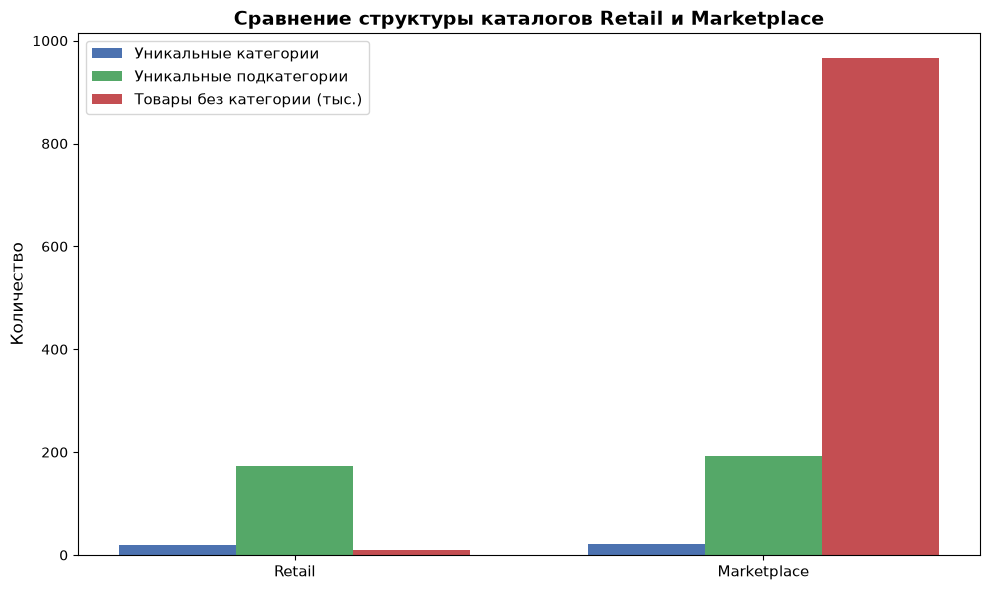

In [14]:
labels = ['Retail', 'Marketplace']
categories_count = [stats['Unique Categories'][0], stats['Unique Categories'][1]]
subcategories_count = [stats['Unique Subcategories'][0], stats['Unique Subcategories'][1]]
null_cat_count = [stats['Null Categories'][0], stats['Null Categories'][1]]

x = np.arange(len(labels))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

rects1 = ax.bar(x - width, categories_count, width, label='Уникальные категории', color='#4C72B0')
rects2 = ax.bar(x, subcategories_count, width, label='Уникальные подкатегории', color='#55A868')

null_cat_k = [n / 1000 for n in null_cat_count]
rects3 = ax.bar(x + width, null_cat_k, width, label='Товары без категории (тыс.)', color='#C44E52')

ax.set_ylabel('Количество', fontsize=12)
ax.set_title('Сравнение структуры каталогов Retail и Marketplace', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11)
ax.legend(fontsize=11)

fig.tight_layout()
plt.show()

### Анализ пропусков в товарах (Retail vs Marketplace)

* **Retail (Ритейл):** Данные заполнены почти идеально. Пропуск по категориям всего **3.83%**, по ценам — **0.29%**, а эмбеддинги заполнены на **100%**. Это говорит о высоком качестве структурирования оффлайн/универсального ритейла.

* **Marketplace (Маркетплейс):** Здесь картина другая. Категории пропущены у **41.56%** товаров, а подкатегории — у **53.02%**.
Возможно -  анонимные или неразмеченные товарные позиции.
Удалять этот массив жесткими фильтрами по категориям нельзя — мы потеряем половину каталога. Наша стратегия — использовать **300-мерные эмбеддинги** (у которых пропусков почти нет — 73 штуки на 2.3 млн товаров), чтобы семантически связывать и кластеризовать товары независимо от текстовых тегов.

### 1.4 Выбросы: Пользователи с аномальным кол-вом событий - боты, парсеры, нужно отсеять

Поиск выбросов (ботов/парсеров) по логам событий за день (01082). Распредление активности пользователе:

In [15]:
user_activity = (
    df_retail_events
    .group_by('user_id')
    .len(name='event_count')
    .sort('event_count', descending=True)
)
print(user_activity.describe())

shape: (9, 3)
┌────────────┬─────────────┬─────────────┐
│ statistic  ┆ user_id     ┆ event_count │
│ ---        ┆ ---         ┆ ---         │
│ str        ┆ f64         ┆ f64         │
╞════════════╪═════════════╪═════════════╡
│ count      ┆ 2208.0      ┆ 2208.0      │
│ null_count ┆ 0.0         ┆ 0.0         │
│ mean       ┆ 4.4529e7    ┆ 175.408514  │
│ std        ┆ 2.5903e7    ┆ 1510.98761  │
│ min        ┆ 110707.0    ┆ 1.0         │
│ 25%        ┆ 2.2438657e7 ┆ 2.0         │
│ 50%        ┆ 4.4471389e7 ┆ 7.0         │
│ 75%        ┆ 6.676368e7  ┆ 20.0        │
│ max        ┆ 8.9823566e7 ┆ 41191.0     │
└────────────┴─────────────┴─────────────┘


**Распределение активности пользователей (`event_count`):**

* Медиана (50%) составляет всего **7 событий в день**, а 75% пользователей делают **до 20 событий**.

* Пользователи с максимальным кол-вом событий (`max`) з **41 191 событием за сутки**.

Посмотрим на топ-5 самых «активных» пользователей (кандидаты в боты):

In [16]:
print(user_activity.head(5))

shape: (5, 2)
┌──────────┬─────────────┐
│ user_id  ┆ event_count │
│ ---      ┆ ---         │
│ u64      ┆ u32         │
╞══════════╪═════════════╡
│ 38365565 ┆ 41191       │
│ 25095614 ┆ 30939       │
│ 31594993 ┆ 24970       │
│ 818418   ┆ 20445       │
│ 17734600 ┆ 17005       │
└──────────┴─────────────┘


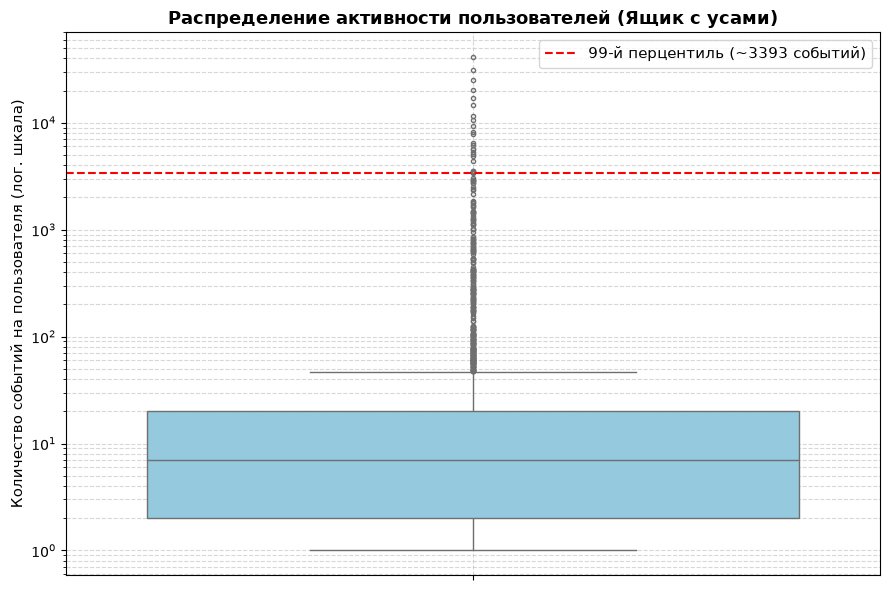

In [17]:
# Считаем количество событий на каждого пользователя
user_activity_boxplot = (
    df_retail_events
    .group_by('user_id')
    .len(name='event_count')
    .to_pandas() # переводим в pandas для интеграции с seaborn/matplotlib
)

# Строим график
plt.figure(figsize=(9, 6))

# Используем логическую шкалу (log scale), так как разброс от 1 до 40000 колоссальный
sns.boxplot(y=user_activity_boxplot['event_count'], color='skyblue', fliersize=3)
plt.yscale('log')

plt.title('Распределение активности пользователей (Ящик с усами)', fontsize=13, fontweight='bold')
plt.ylabel('Количество событий на пользователя (лог. шкала)', fontsize=11)
plt.grid(True, which="both", ls="--", alpha=0.5)

# Добавим поясняющую линию уровня 99-го перцентиля (граница отсечения ботов)
p99 = user_activity_boxplot['event_count'].quantile(0.99)
plt.axhline(y=p99, color='red', linestyle='--', label=f'99-й перцентиль (~{p99:.0f} событий)')
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

**Вывод:**

Обычный человек не может кликать, просматривать или добавлять товары в корзину каждые 2 секунды на протяжении 24 часов. Это скрипты, парсеры, боты или автоматизированные системы сбора цен/каталогов.

**Решение:**

На этапе подготовки датасета к ML мы введем жесткую фильтрацию (например, отсекать пользователей выше 99-го перцентиля или по разумному порогу, скажем, > 200–500 событий в день), чтобы эти боты не искажали нам метрики рекомендательной модели.


## 2 Поведение признаков:

### 2.1 Анализируем категории и подкатегории, ищем схожие категории в данных из ритейла и маркетплейса

Смотрим справочники категорий:

In [18]:
print("Уникальных категорий в Retail:", df_retail_items['category'].n_unique())
print("Уникальных категорий в Marketplace:", df_market_items['category'].n_unique())

Уникальных категорий в Retail: 21
Уникальных категорий в Marketplace: 23


Посмотрим списки категорий в ритейле и маркетплейсе:

In [19]:
print("\nКатегории в Retail:")
print(df_retail_items['category'].drop_nulls().unique().to_list())

print("\nКатегории в Marketplace (первые 10):")
print(df_market_items['category'].drop_nulls().unique().head(10).to_list())


Категории в Retail:
['Office Supplies and Educational Materials', 'Automotive Accessories, Spare Parts, and Car Care Products', 'Home Improvement and Countryside Retreat Essentials', 'Construction and Renovation Materials, Tools, and Equipment', 'Home/Office Furniture and Interior Decor', 'Pharmaceuticals and Medical Supplies', 'Other', 'Outerwear, Casual Apparel, and Specialized Workwear', 'Pet Supplies: Food, Accessories, and Grooming Products', 'Foodstuffs and Beverages', "Children's Products and Childcare Items", 'Printed Media: Publications, Textbooks, and Fiction', 'Cleaning Supplies and Everyday Household Items', 'Electronic Devices and Gadgets', 'Household Electrical Appliances', 'Sports Equipment, Gear, and Outdoor Activity Accessories', 'Footwear of All Types', 'Cosmetics, Personal Care, and Health Maintenance Products', 'Hobby, Creative, and Leisure Products', 'Fashion Accessories, Tech Add-ons, and Style Enhancements']

Категории в Marketplace (первые 10):
['Pet Supplies: 

### 2.1 Анализируем пересечение пользователей из ритейла и маркетплейса

Анализ пересечения пользователей по одному из дней (например, 01082):

In [20]:
retail_users = set(df_retail_events['user_id'].unique().to_list())
market_users = set(df_market_events['user_id'].unique().to_list())

intersection_users = retail_users.intersection(market_users)

print(f"Активных в Retail: {len(retail_users)}")
print(f"Активных в Marketplace: {len(market_users)}")
print(f"Активных в ОБИХ каналах в один и тот же день: {len(intersection_users)}")
print(f"Доля пересечения от Retail-аудитории: {len(intersection_users) / len(retail_users) * 100:.2f}%")

Активных в Retail: 2208
Активных в Marketplace: 58321
Активных в ОБИХ каналах в один и тот же день: 855
Доля пересечения от Retail-аудитории: 38.72%


Возьмем один день для демонстрации:

Строим диаграмму Венна:

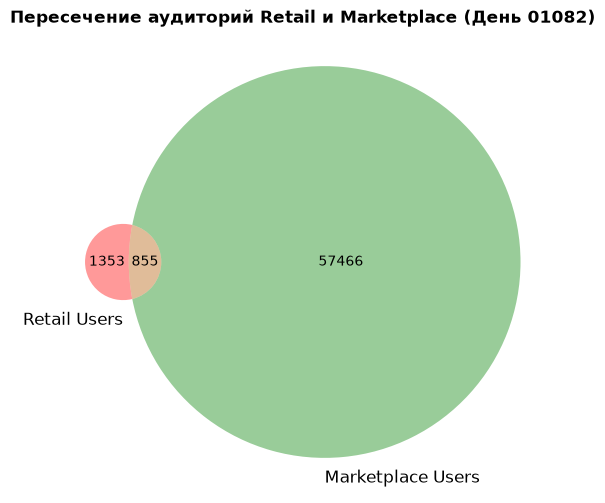

In [21]:
day = '01082'
plt.figure(figsize=(8, 6))
v = venn2(
    subsets=(len(retail_users) - len(retail_users.intersection(market_users)),
             len(market_users) - len(retail_users.intersection(market_users)),
             len(retail_users.intersection(market_users))),
    set_labels=('Retail Users', 'Marketplace Users')
)

plt.title(f"Пересечение аудиторий Retail и Marketplace (День {day})", fontsize=12, fontweight='bold')
plt.show()

**Вывод:**
1. Сопоставимость каталогов (Категории):

* Списки категорий в Retail и Marketplace практически идентичны («Children's Products», «Pet Supplies», «Foodstuffs», «Electronics» и т.д.).

* Это значит, что пространство товаров семантически выровнено. Мы можем напрямую сопоставлять покупки человека в оффлайн-ритейле с его интересами на маркетплейсе по одним и тем же категориальным тегам (или через 300-мерные эмбеддинги).

2. Пользователи для кроссдоменных рекомендаций:

* За один день в ритейле активны 2 208 пользователей, а на маркетплейсе - почти 58 тысяч. При этом из относительно небольшой ритейл-аудитории почти 39% (855 человек) в тот же самый день заходят на маркетплейс.

Можно сделать вывод, что экосистема едина: пользователи не разделены изолированно только в супермаркете у дома или только на маркетплейсе. Они перетекают между каналами.

## 3 Выводы:

### 3.1 Наличие событий пользователей в retail/marketplace данных дает возможность кроссдоменной рекомендации.

* Датасет обладает высокой степенью связности. Несмотря на пропуски в категориях маркетплейса (~40–50%), наличие плотных 300-мерных эмбеддингов и четких идентификаторов пользователей (`user_id`) позволяет построить единый профиль клиента.

* Асимметрия доменов: Ритейл и маркетплейс имеют разную плотность данных (каталог маркетплейса больше в 10 раз), что требует весовой балансировки при построении совместных векторных представлений.

### 3.2 Существует возможность рекомендации по категории продукта.

* ~39% активной аудитории ритейла ежедневно присутствуют на маркетплейсе. Это подтверждает возможность решения проблемы «холодного старта» на маркетплейсе за счет истории оффлайн-покупок в ритейле.

* Выявление аномалий (ботов): Анализ распределения активности выявил наличие автоматизированных скриптов (>40 тыс. событий у отдельных `user_id` в сутки). Это требует обязательной фильтрации (отсечения выбросов по перцентилям) на этапе подготовки обучающей выборки.

### 3.3 Существует возможность рекомендации по профилю пользователя (родители, кошатники, уровень дохода).

* Сегментация: Выделение стабильных групп (родители, владельцы домашних животных) по категориям ритейла (`Children's Products`, `Pet Supplies`).

* Кросс-продажи (Cross-Selling): Использование оффлайн-контекста для генерации релевантных онлайн-рекомендаций на маркетплейсе (например, предложение сопутствующих товаров для ухода за ребенком или питомцем).

### 3.4 Товары без категории нельзя рекомендовать, но можно использовать для анализа пользователей.

* Наличие пропусков категорий на маркетплейсе компенсируется их 300-мерными эмбеддингами. Семантическая близость векторов позволяет находить скрытые паттерны поведения пользователей даже для неразмеченного «длинного хвоста» товаров.

